# Baseline: PCA Reconstruction Error

Before training any autoencoder, we need a reference point: how well does a simple, non-deep method do on the same data?

**Why PCA?** PCA is the linear version of an autoencoder. It compresses each row to a few principal components and reconstructs it back. Like an autoencoder trained on benign traffic only, it reconstructs normal traffic well and attacks poorly, so the reconstruction error is the anomaly score.

If an autoencoder cannot beat PCA, the non-linear (deep) part adds nothing. Uses the shared data and `evaluate.py`, exactly like the autoencoder notebooks.

In [ ]:
!git clone -q https://github.com/JanaAlzobidi/iomt-anomaly-detection.git

In [2]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

REPO = "/content/iomt-anomaly-detection"
DATA_DIR = f"{REPO}/data"
RESULTS_DIR = f"{REPO}/results"
os.makedirs(f"{RESULTS_DIR}/figures", exist_ok=True)
sys.path.insert(0, REPO)
from evaluate import load_data, evaluate, compare_percentiles

SEED = 42
X_train, X_val, X_test, y_test, attack_test = load_data(DATA_DIR)

X_train (150000, 40) (benign only) | X_val (30000, 40) (benign only) | X_test (42893, 40), attacks: 5286 (12.3%)


## 1. Choosing the number of components

We keep the smallest number of components that explains 95% of the variance of the benign training data. This plays the same role as the bottleneck size in an autoencoder.

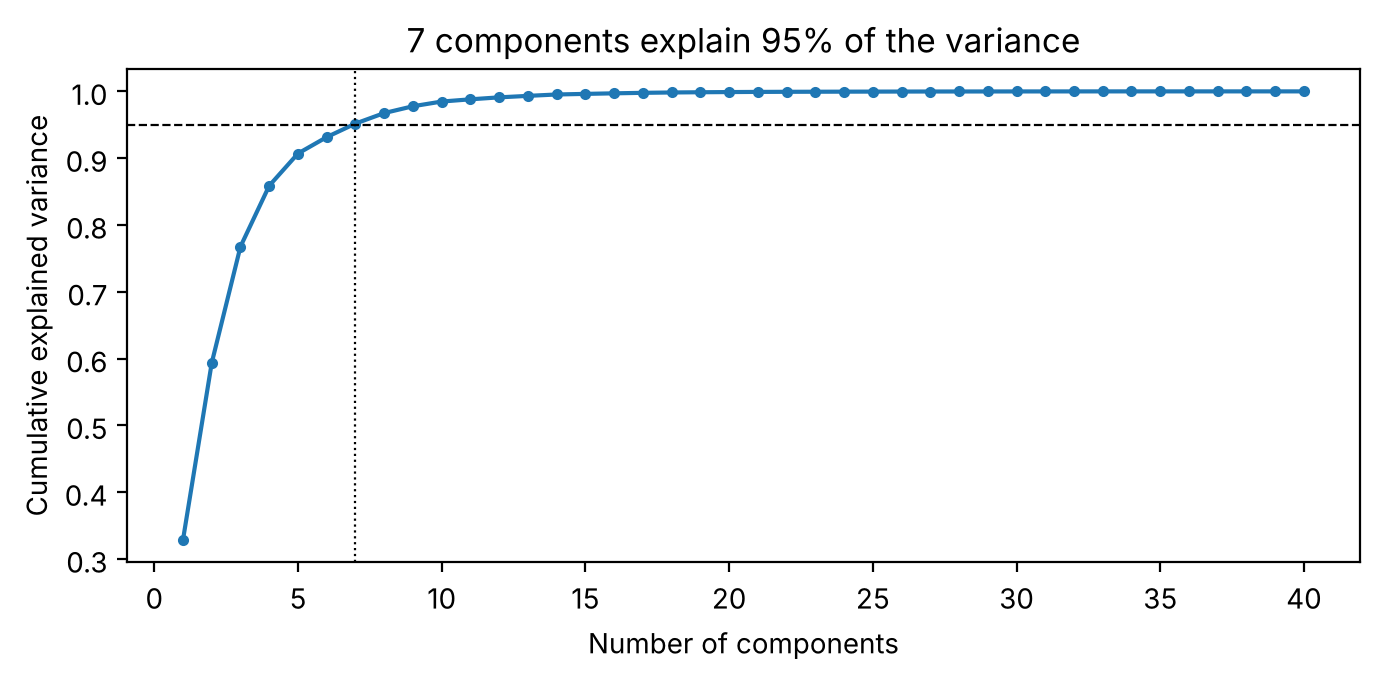

In [3]:
full = PCA(random_state=SEED).fit(X_train)
cum = np.cumsum(full.explained_variance_ratio_)
k = int(np.searchsorted(cum, 0.95) + 1)

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, len(cum) + 1), cum, marker="o", ms=3)
plt.axhline(0.95, color="k", ls="--", lw=0.8)
plt.axvline(k, color="k", ls=":", lw=0.8)
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title(f"{k} components explain 95% of the variance")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/figures/pca_explained_variance.png", dpi=120); plt.show()

## 2. Fit on benign training data and score

In [4]:
pca = PCA(n_components=k, random_state=SEED).fit(X_train)

def pca_errors(X):
    """Per-row MSE between the input and its PCA reconstruction."""
    recon = pca.inverse_transform(pca.transform(X))
    return np.mean((X - recon) ** 2, axis=1)

val_scores = pca_errors(X_val)
test_scores = pca_errors(X_test)
print(f"components: {k} | input features: {X_train.shape[1]}")

components: 7 | input features: 40


## 3. Evaluation

Same rule as every model: the threshold is the 99th percentile of the validation (benign) scores.


===== Baseline: PCA =====
Threshold (P99 of validation scores): 0.0134322
          roc_auc: 0.9380
           pr_auc: 0.8347
               f1: 0.7614
        precision: 0.9594
           recall: 0.6311
 false_alarm_rate: 0.0037

Confusion matrix (rows = true, cols = predicted)
        Benign  Attack
Benign   37466     141
Attack    1950    3336

Recall per attack type (weakest first):
                           n recall
type                               
ARP Spoofing             300  0.010
MQTT Malformed Data      300  0.040
MQTT DoS Connect Flood   300  0.063
MQTT DoS Publish Flood   300  0.127
MQTT DDoS Publish Flood  300  0.137
MQTT DDoS Connect Flood  300  0.290
Recon PingSweep          186  0.376
Recon VulScan            300  0.403
Recon OSScan             300  0.883
Recon PortScan           300  0.953
DoS TCP Flood            300  0.993
DoS ICMP Flood           300  0.993
DDoS UDP Flood           300  0.997
DoS UDP Flood            300  0.997
DoS SYN Flood            300  1.0

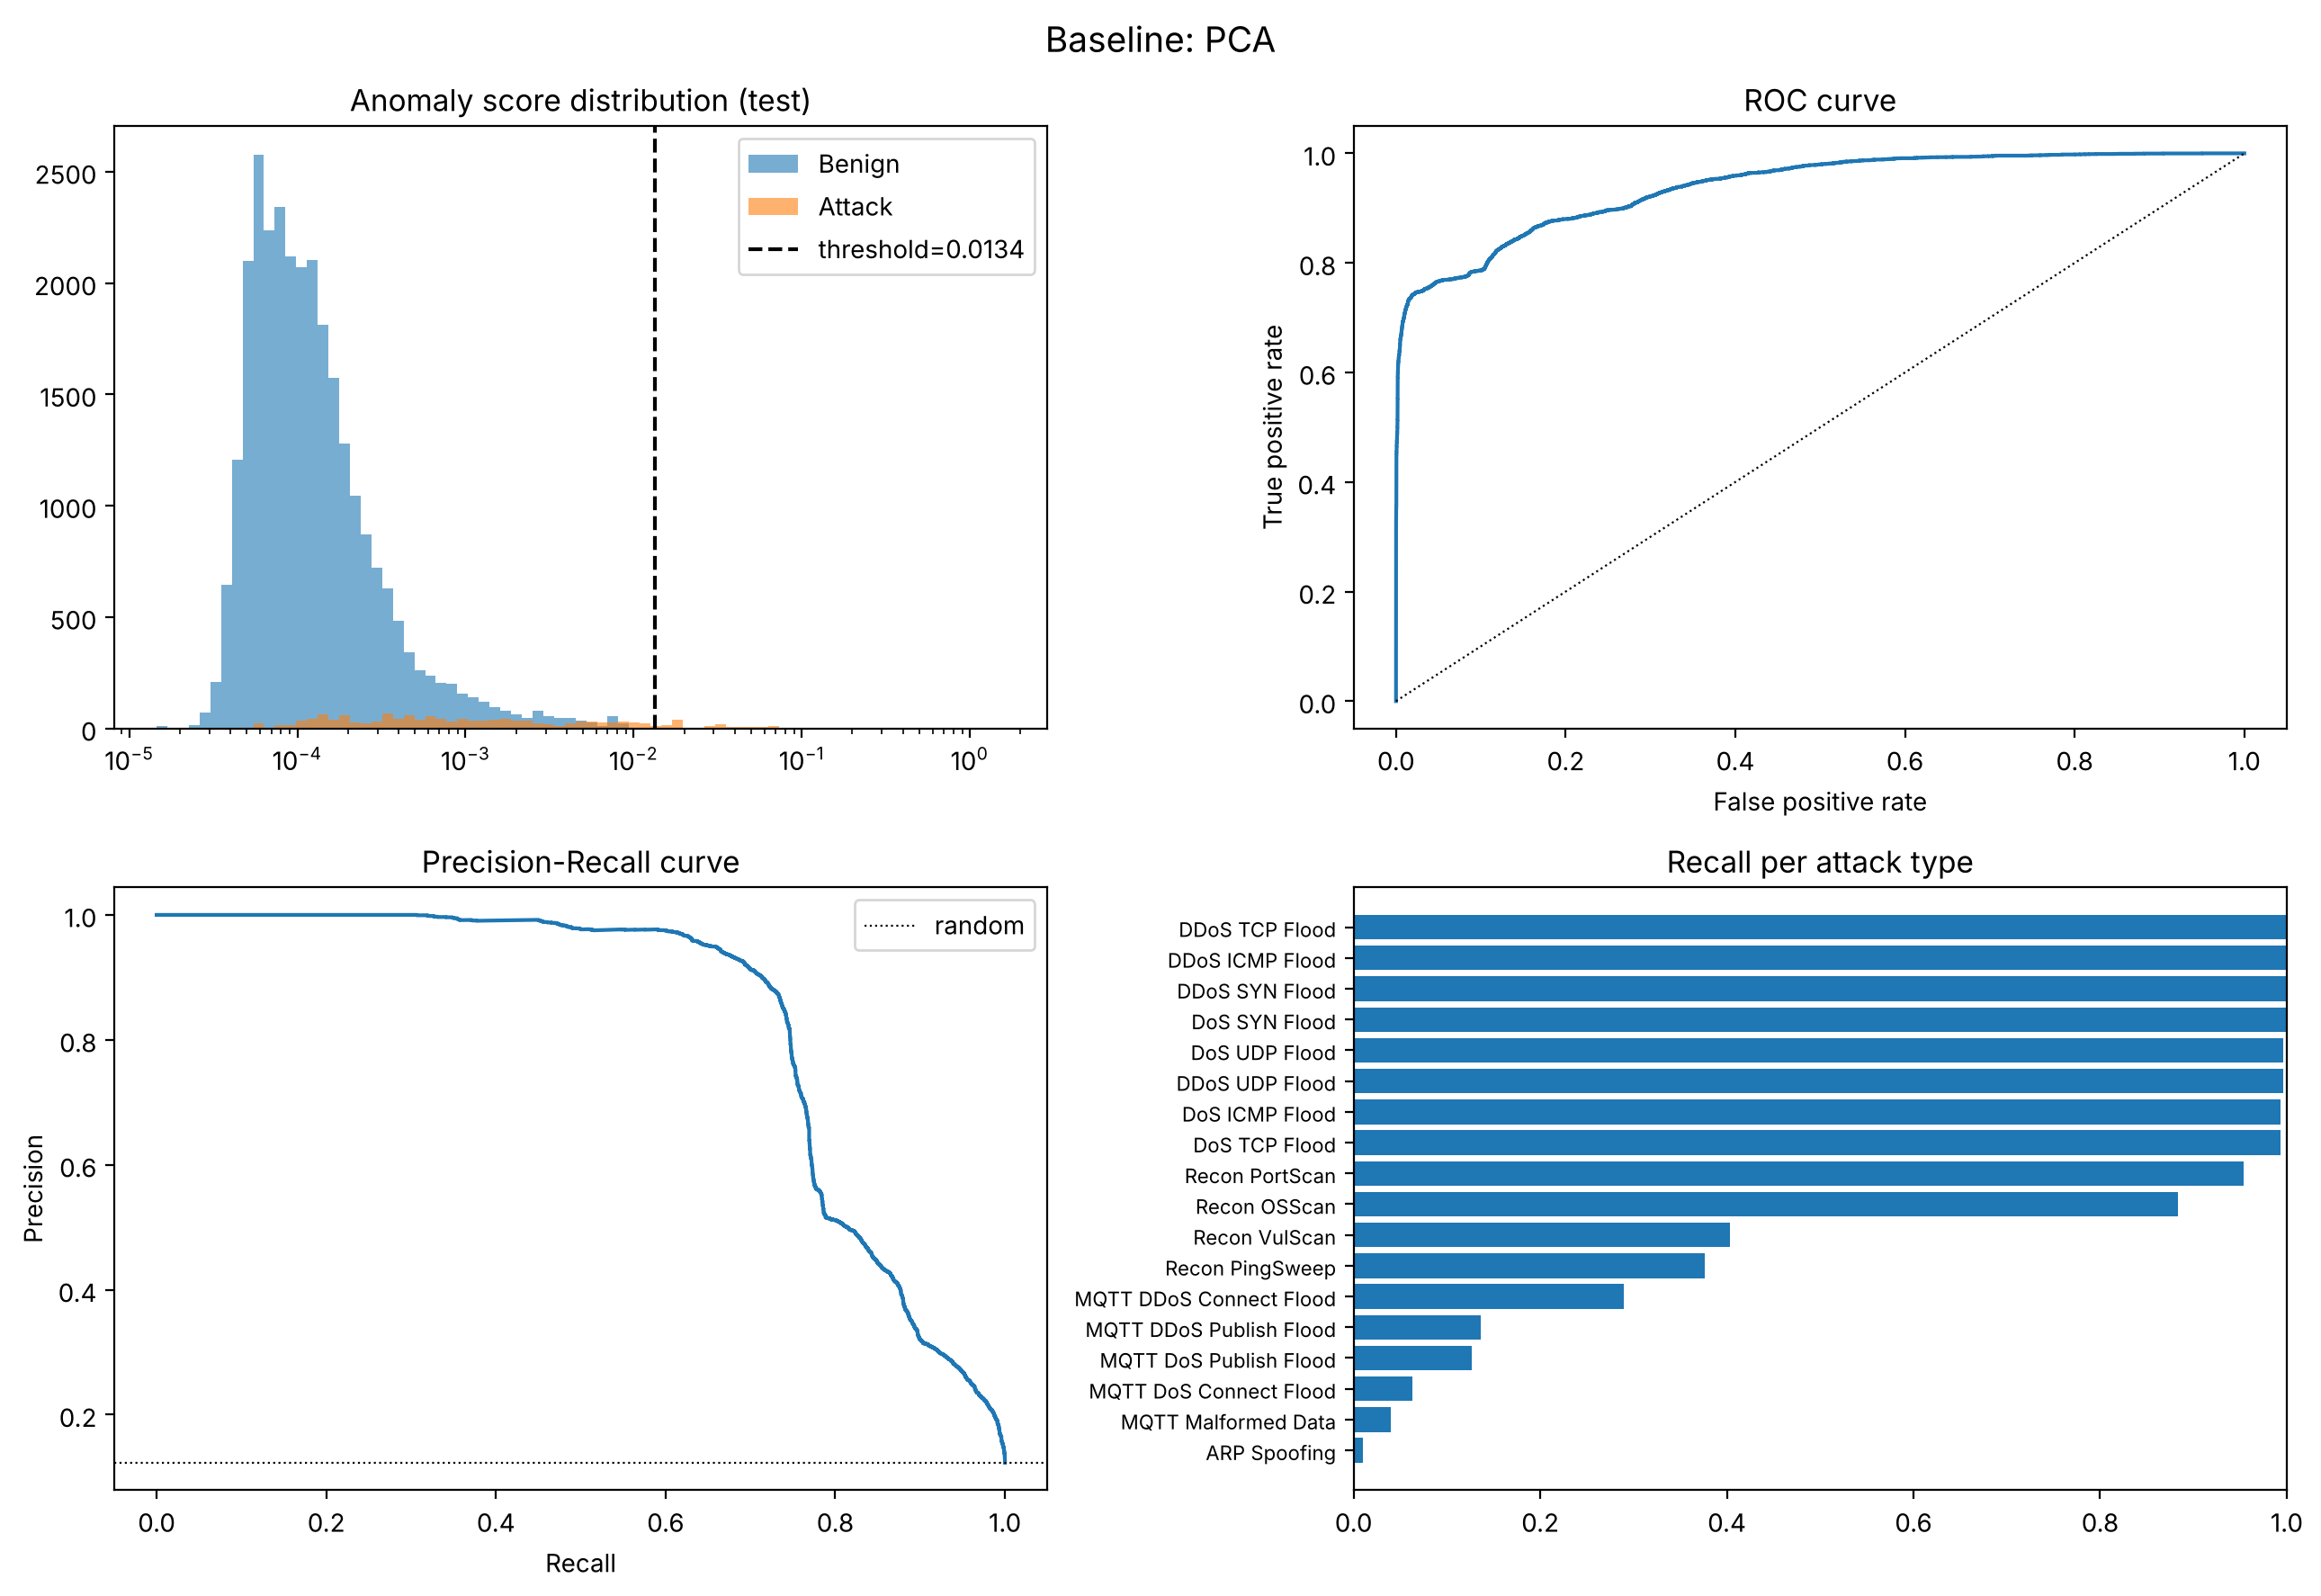


Saved to /content/iomt-anomaly-detection/results/results.csv


In [5]:
res = evaluate(test_scores, y_test, attack_test, val_scores,
               model_name="Baseline: PCA", person="baseline", save_dir=RESULTS_DIR)

In [6]:
compare_percentiles(test_scores, y_test, val_scores);

 percentile  threshold     f1  recall  false_alarm_rate
    95.0000     0.0063 0.6212  0.8093            0.1119
    99.0000     0.0134 0.7614  0.6311            0.0037
    99.5000     0.0204 0.6487  0.4845            0.0013


## 4. What the autoencoders need to beat

The table below is the target. The attacks with the lowest recall are where a non-linear model can add value.

In [7]:
per_attack = pd.Series(res["per_attack_recall"]).sort_values()
print(f"F1 to beat: {res['f1']:.3f} | PR-AUC to beat: {res['pr_auc']:.3f}\n")
print("Weakest attacks for PCA:")
print(per_attack.head(8).to_string(float_format="{:.3f}".format))

F1 to beat: 0.761 | PR-AUC to beat: 0.835

Weakest attacks for PCA:
ARP Spoofing              0.010
MQTT Malformed Data       0.040
MQTT DoS Connect Flood    0.063
MQTT DoS Publish Flood    0.127
MQTT DDoS Publish Flood   0.137
MQTT DDoS Connect Flood   0.290
Recon PingSweep           0.376
Recon VulScan             0.403
